# Homework 4 — Evaluation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)

cat_features = ['lead_source', 'industry', 'employment_status', 'location']
num_features = ['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score']
target = 'converted'

In [2]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [3]:
df[cat_features] = df[cat_features].fillna('NA')
df[num_features] = df[num_features].fillna(0.0)

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
y_train = df_train[target].values
y_val = df_val[target].values

## Q1. ROC AUC feature importance

In [5]:
aucs = {}
for col in num_features:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    aucs[col] = auc

pd.Series(aucs).sort_values(ascending=False)

lead_score                  0.788225
interaction_count           0.764920
number_of_courses_viewed    0.722989
annual_income               0.608198
dtype: float64

## Q2. Training the model

In [6]:
features = cat_features + num_features

def train(df, y, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df[features].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model

def predict(df, dv, model):
    X = dv.transform(df[features].to_dict(orient='records'))
    return model.predict_proba(X)[:, 1]

dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
round(roc_auc_score(y_val, y_pred), 3)

0.732

## Q3. Precision and Recall

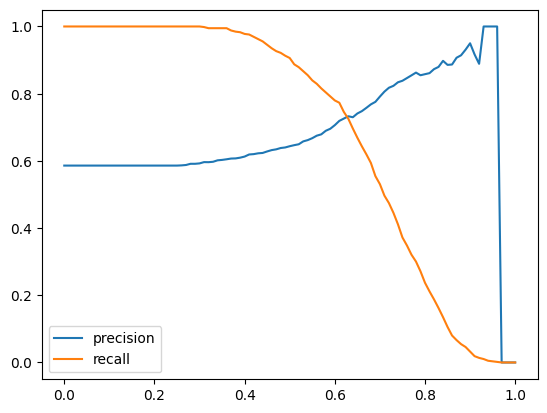

In [7]:
scores = []
for t in np.arange(0.0, 1.01, 0.01):
    pred = y_pred >= t
    tp = (pred & (y_val == 1)).sum()
    fp = (pred & (y_val == 0)).sum()
    fn = (~pred & (y_val == 1)).sum()
    p = tp / (tp + fp) if tp + fp > 0 else 0.0
    r = tp / (tp + fn) if tp + fn > 0 else 0.0
    scores.append((round(t, 2), p, r))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.legend()
plt.show()

In [8]:
nonzero = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)]
diff = (nonzero.precision - nonzero.recall).abs()
nonzero.loc[diff.idxmin()]

threshold    0.630000
precision    0.732759
recall       0.725256
Name: 63, dtype: float64

## Q4. F1 score

In [9]:
p, r = df_scores.precision, df_scores.recall
df_scores['f1'] = np.where(p + r > 0, 2 * p * r / (p + r), 0.0)
df_scores.loc[df_scores.f1.idxmax()]

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

## Q5. 5-Fold CV

In [10]:
def cv_scores(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]
        dv, model = train(df_tr, df_tr[target].values, C=C)
        aucs.append(roc_auc_score(df_va[target].values, predict(df_va, dv, model)))
    return aucs

aucs = cv_scores(1.0)
print(np.round(aucs, 3), round(np.std(aucs), 3))

[0.731 0.73  0.736 0.741 0.721] 0.007


## Q6. Hyperparameter Tuning

In [11]:
for C in [0.000001, 0.001, 1]:
    aucs = cv_scores(C)
    print(C, round(np.mean(aucs), 3), round(np.std(aucs), 3))

1e-06 0.617 0.019


0.001 0.749 0.01


1 0.732 0.007
